# 83장 · 오류 재현·수정·검증

이미 체크된 할 일에 다시 완료 요청을 보냈더니 체크 표시가 풀렸습니다. 첫 클릭만 확인하면 숨어 버리는 오류입니다. 82장의 API가 받는 명시적 completed 값을 유지한 채 같은 요청을 두 번 보내 결함을 재현합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 첫 요청에서는 드러나지 않는 오류

제공된 faulty 저장소는 completed=True 요청을 ‘현재 값을 뒤집기’로 처리합니다. 같은 ID, 같은 초기 상태, 같은 입력을 사용해야 수정 전후 결과를 비교할 수 있습니다.



**볼 곳**　같은 요청을 두 번 보낸 뒤 두 번째 칸의 값이 다시 False가 되는지 보세요.

**애니메이션의 의미**　같은 요청을 두 번 보내면 토글 오류가 드러납니다.

<!-- motion:toggle-rocker -->
**같은 완료 요청을 두 번 보내면 스위치는 어디에 있을까요?**

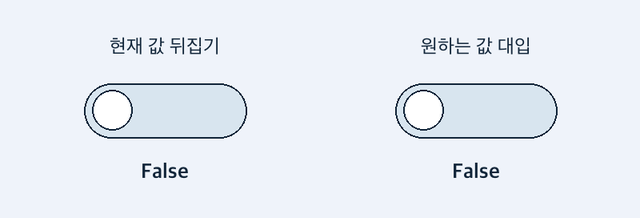

현재 값을 뒤집으면 첫 요청 뒤 True, 재전송 뒤 False입니다. 요청에 적힌 최종값 True를 대입하면 재전송 뒤에도 True가 남습니다.
<!-- /motion -->


### 셀 01 · 두 번째 완료 요청 재현하기

아래 결함은 수업용으로 의도해 넣었습니다. 두 번째 결과를 첫 번째와 비교하세요.

In [1]:
def faulty_update(item, completed):
    item["completed"] = not item["completed"]
    return item["completed"]

item = {"id": 1, "title": "복습", "completed": False}
print(faulty_update(item, True))
print(faulty_update(item, True))

True
False


True 다음에 False가 나옵니다. 두 번 모두 보낸 값은 True였는데 함수는 인자를 읽지 않고 현재 상태만 뒤집었습니다. Codex에 보낼 오류 보고에는 요청 두 건과 두 번째 실제 결과를 함께 적으세요.

## 원하는 최종값을 저장하고 같은 입력 재실행하기

수정 범위를 완료 필드 반영 한 줄에 둡니다. PATCH 요청이 들어온 횟수에 관계없이 명시적으로 전달받은 상태를 저장해야 합니다.



**볼 곳**　재전송 뒤에도 같은 True가 유지되는지 살펴보세요.

**애니메이션의 의미**　최종값을 직접 저장하면 재전송 후에도 값이 같습니다.


### 과제 02 · 완료 상태 반영 코드 수정

원래 함수에서 받은 completed 값을 그대로 대입하고 같은 입력 두 번의 결과를 출력하세요.

In [2]:
def update(item, completed):
    # 요청에 담긴 completed를 반영하세요.
    pass

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>def update(item, completed):
    item[&#x27;completed&#x27;] = completed
    return item[&#x27;completed&#x27;]

row = {&#x27;id&#x27;: 1, &#x27;title&#x27;: &#x27;복습&#x27;, &#x27;completed&#x27;: False}
print(update(row, True), update(row, True))</code></pre>
<p>실행 결과</p><pre><code>True True</code></pre>
<p>True True가 나옵니다. 두 번째 요청을 삭제해서 문제를 숨기지 않고 입력을 동일하게 유지했습니다.</p>
</details>

#### 같은 행에 완료 요청을 두 번 보냈을 때

<table style="width:100%;border-collapse:collapse"><thead><tr><th scope="col">구현</th><th scope="col">첫 요청 True</th><th scope="col">둘째 요청 True</th></tr></thead><tbody><tr><td>셀 01 · 현재 값을 뒤집음</td><td>True</td><td>False</td></tr><tr><td>과제 02 · 요청 값을 저장</td><td>True</td><td>True</td></tr></tbody></table>

### 셀 03 · 완료 해제의 회귀 검사

과제 02에서 완성한 update에 True, True, False를 보내고 매번 반환값과 같은 행의 저장값을 확인합니다.

과제 02에서 작성한 update를 실행한 뒤 이 셀로 오세요. 같은 True 요청을 두 번 보내고 이어 False로 되돌립니다. 셀을 고쳤다면 함수 정의 셀부터 다시 실행하세요.

In [3]:
row = {"id": 5, "title": "복습", "completed": False}
first = update(row, True)
after_first = row.copy()
second = update(row, True)
after_second = row.copy()
last = update(row, False)
if first is None and second is None and last is None:
    print("과제 02의 update를 완성하고 정의 셀부터 다시 실행하세요.")
else:
    assert first is True and second is True, "같은 완료 요청을 반복해도 True를 반환해야 합니다."
    expected = {"id": 5, "title": "복습", "completed": True}
    assert after_first == expected and after_second == expected, "두 완료 요청 모두 원래 행에 저장되어야 합니다."
    assert last is False, "완료 해제 요청은 False를 반환해야 합니다."
    assert row == {"id": 5, "title": "복습", "completed": False}, "같은 행의 ID·제목·완료 값을 확인하세요."
    print("검사 통과", row)

과제 02의 update를 완성하고 정의 셀부터 다시 실행하세요.


시작본에서 과제 02를 비워 두면 update를 완성하라는 안내가 나옵니다. 정답을 넣고 과제 02와 이 셀을 다시 실행했을 때의 마지막 줄은 다음과 같습니다.

검사 통과 {'id': 5, 'title': '복습', 'completed': False}

완료 요청을 두 번 보낸 뒤 해제했으므로 마지막 값은 False입니다. 요청할 때마다 상태를 뒤집는 구현은 두 번째 True 검사에서 멈춥니다.

## 돌아보기

수정 요청의 입력·기대·실제를 다른 팀원에게 보여 주고 초기 상태부터 재현하게 해 보세요. 같은 결과를 보지 못한다면 게시된 코드를 더 바꾸기 전에 사용한 저장소와 초기 데이터를 비교하세요.